# Customer Segmentation Analysis (RFM + K-Means)

**Objective:** Apply clustering to segment an e-commerce company's customers by purchasing behaviour, enabling targeted marketing strategies.

**Tech stack:** Python, pandas, scikit-learn (KMeans), matplotlib, seaborn, Jupyter Notebook

**Dataset:** *Online Retail II* (UCI Machine Learning Repository, also on Kaggle). Transactions of a UK-based online gift-ware retailer, Dec 2009 to Dec 2011.

**Approach:** transactions → cleaning → customer-level RFM features → log transform + `StandardScaler` → K-Means (elbow + silhouette) → cluster profiling → marketing actions.

### Dataset notes
- Data is from 2009-2011 and in GBP (£). The aim is to demonstrate the segmentation **method**; findings apply to this retailer in that period, not to online shoppers today.
- Many customers are wholesalers, so a few very large buyers inflate spend (handled with a log transform).
- The RFM snapshot date is set from the dataset's own last date, not today's date.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import warnings; warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
RANDOM_STATE = 42

## 1. Load dataset, inspect structure, handle missing and inconsistent data

In [13]:
df = pd.read_csv("/content/online_retail_II.csv.zip", encoding="ISO-8859-1")


print("Original columns:", df.columns.tolist())
df = df.rename(columns={"Invoice": "InvoiceNo", "Price": "UnitPrice",
                        "Customer ID": "CustomerID", "Customer_ID": "CustomerID"})

print("Shape:", df.shape)
print("\nDtypes:\n", df.dtypes)
print("\nNull values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Cancelled invoices (start with 'C'):", df["InvoiceNo"].astype(str).str.startswith("C").sum())
print("Quantity <= 0:", (df["Quantity"] <= 0).sum(), "| UnitPrice <= 0:", (df["UnitPrice"] <= 0).sum())
df.head()

Original columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']
Shape: (1067371, 8)

Dtypes:
 InvoiceNo       object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID     float64
Country         object
dtype: object

Null values:
 InvoiceNo           0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     243007
Country             0
dtype: int64

Duplicate rows: 34335
Cancelled invoices (start with 'C'): 19494
Quantity <= 0: 22950 | UnitPrice <= 0: 6207


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


In [3]:
n0 = len(df)
log = {}

d = df.dropna(subset=["CustomerID"]);                                   log["1. Missing CustomerID"] = n0 - len(d)
n = len(d); d = d.drop_duplicates();                                    log["2. Duplicate rows"] = n - len(d)
n = len(d); d = d[~d["InvoiceNo"].astype(str).str.startswith("C")];     log["3. Cancelled invoices"] = n - len(d)
n = len(d); d = d[(d["Quantity"] > 0) & (d["UnitPrice"] > 0)];          log["4. Non-positive quantity/price"] = n - len(d)
non_product = r"^(POST|DOT|M|BANK CHARGES|AMAZONFEE|ADJUST.*|C2|CRUK)$"
n = len(d); d = d[~d["StockCode"].astype(str).str.match(non_product, case=False)]; log["5. Non-product stock codes"] = n - len(d)

df = d.copy()
df["CustomerID"]  = df["CustomerID"].astype(int)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["Revenue"]     = df["Quantity"] * df["UnitPrice"]

display(pd.Series(log, name="rows removed").to_frame())
print(f"Kept {len(df):,} of {n0:,} rows ({len(df)/n0:.0%})")
print("Date range:", df["InvoiceDate"].min().date(), "to", df["InvoiceDate"].max().date())
print("Unique customers:", df["CustomerID"].nunique())

,rows removed
1. Missing CustomerID,243007
2. Duplicate rows,26479
3. Cancelled invoices,18390
4. Non-positive quantity/price,70
5. Non-product stock codes,2814


Kept 776,611 of 1,067,371 rows (73%)
Date range: 2009-12-01 to 2011-12-09
Unique customers: 5852


### Observations: data quality
- **Problems found:** The dataset contained the following data quality issues:
  - Missing Customer IDs: 243,007 rows
  - Duplicate records: 26,479 rows
  - Cancelled invoices: 18,390 rows
  - Non-positive quantity or price: 70 rows
  - Non-product stock codes: 2,814 rows
- **Handling:** each problem has one explicit rule (see the code). Rows without `CustomerID` cannot be assigned to a customer, so they are dropped; cancellations and non-positive values would distort Monetary.
- **Result:** After data cleaning and preprocessing, 776,611 rows (73%) were retained from the original 1,067,371 records.
  - Date Range: December 1, 2009 – December 9, 2011
  - Unique Customers: 5,852

- **Conclusion:** The data cleaning process removed incomplete, duplicate, invalid, and irrelevant records, resulting in a cleaner and more reliable dataset for further Exploratory Data Analysis (EDA).

## 2. Descriptive statistics

,mean,median,std,min,max
avg_purchase_value,381.08,277.87,"1,212.59",2.95,"84,236.25"
orders,6.26,3.00,12.75,1.00,373.00
clv,"2,916.82",856.02,"14,307.19",2.95,"580,987.04"


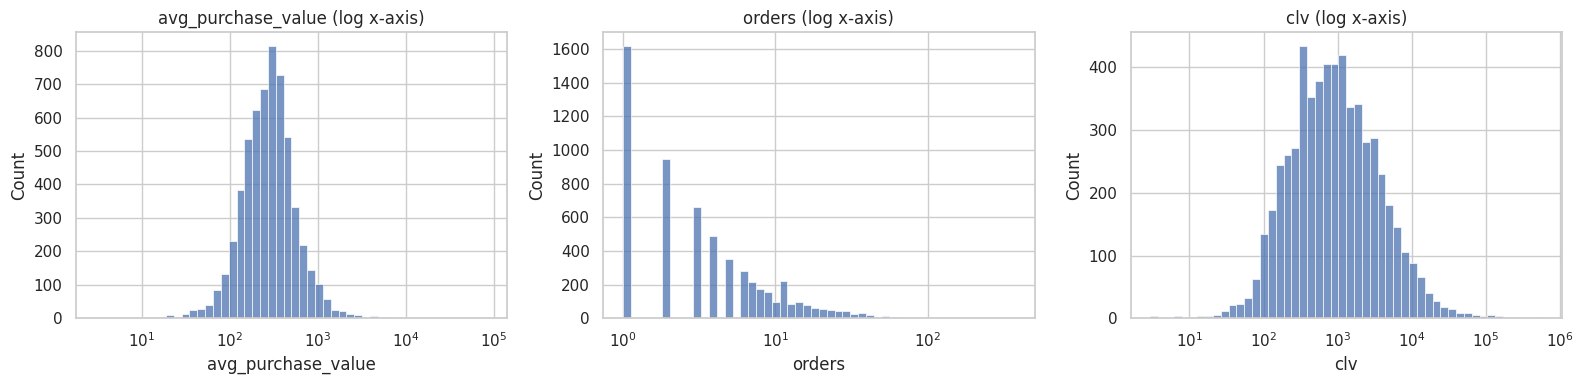

In [4]:
cust = df.groupby("CustomerID").agg(
    total_spend=("Revenue", "sum"),
    orders=("InvoiceNo", "nunique"),
    first_purchase=("InvoiceDate", "min"),
    last_purchase=("InvoiceDate", "max"),
)
cust["avg_purchase_value"] = cust["total_spend"] / cust["orders"]
cust["clv"] = cust["total_spend"]    # historical customer lifetime value

stats = cust[["avg_purchase_value", "orders", "clv"]].agg(["mean", "median", "std", "min", "max"]).T
display(stats)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, c in zip(ax, ["avg_purchase_value", "orders", "clv"]):
    sns.histplot(cust[c], bins=50, log_scale=True, ax=a).set_title(f"{c} (log x-axis)")
plt.tight_layout(); plt.show()

### Observations: descriptive statistics
- **Definitions:** average purchase value = total spend ÷ number of orders; purchase frequency = number of unique orders; CLV = historical total spend (not a predicted value).
- **Key observation:** - verage Purchase Value: Mean (381.08) > Median (277.87), indicating a few customers make unusually large purchases.
  - Orders: Mean (6.26) > Median (3), suggesting a small group of customers places frequent orders.
  - CLV: Mean (2,916.82) > Median (856.02), showing that a few high-value customers contribute significantly to revenue.
  - Key Insight: Customer spending is highly skewed, likely due to a few wholesale or high-value buyers.
  - Recommendation: Segment high-value customers separately and focus on retaining them.
- **Why it matters:** heavy right skew means raw values would dominate the clustering, so a log transform is applied before scaling.

## 3. Feature selection: RFM

Snapshot date: 2011-12-10


,Recency,Frequency,Monetary
count,"5,852.00","5,852.00","5,852.00"
mean,200.20,6.26,"2,916.82"
std,208.51,12.75,"14,307.19"
min,1.00,1.00,2.95
25%,25.00,1.00,339.57
50%,95.00,3.00,856.02
75%,379.00,7.00,"2,241.03"
max,739.00,373.00,"580,987.04"


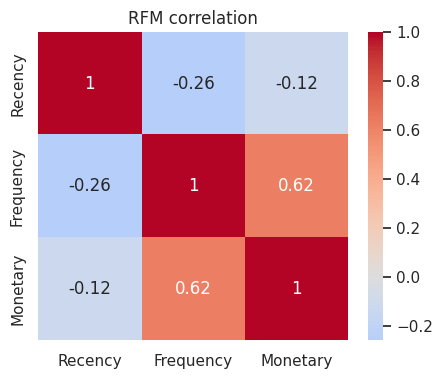

In [5]:
snapshot = df["InvoiceDate"].max() + pd.Timedelta(days=1)   # dataset's own end date, not today

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
)
print("Snapshot date:", snapshot.date())
display(rfm.describe())

plt.figure(figsize=(5, 4))
sns.heatmap(rfm.corr(), annot=True, cmap="coolwarm", center=0)
plt.title("RFM correlation"); plt.show()

### Observations: RFM features
- **Features chosen:** **Recency** (days since last purchase; lower is better), **Frequency** (number of orders; higher is better), **Monetary** (total spend; higher is better). Together they capture how recently, how often and how much a customer buys.
- **Key observation:** Frequency & Monetary: Strong positive correlation (0.62), meaning customers who order more tend to spend more.



  Recency & Frequency: Weak negative correlation (-0.26), indicating customers who purchased recently tend to order more frequently.



  Recency & Monetary: Weak negative correlation (-0.12), showing a slight relationship between recent purchases and spending.



  Key Insight: Frequency and Monetary are closely related, while Recency has weak negative relationships with both.



  Recommendation: Focus on frequent, high-spending customers to improve customer retention and revenue.
- **Why it matters:** three behavioural features are compact, interpretable and standard for segmentation.

## 4. Normalisation (log transform + StandardScaler)

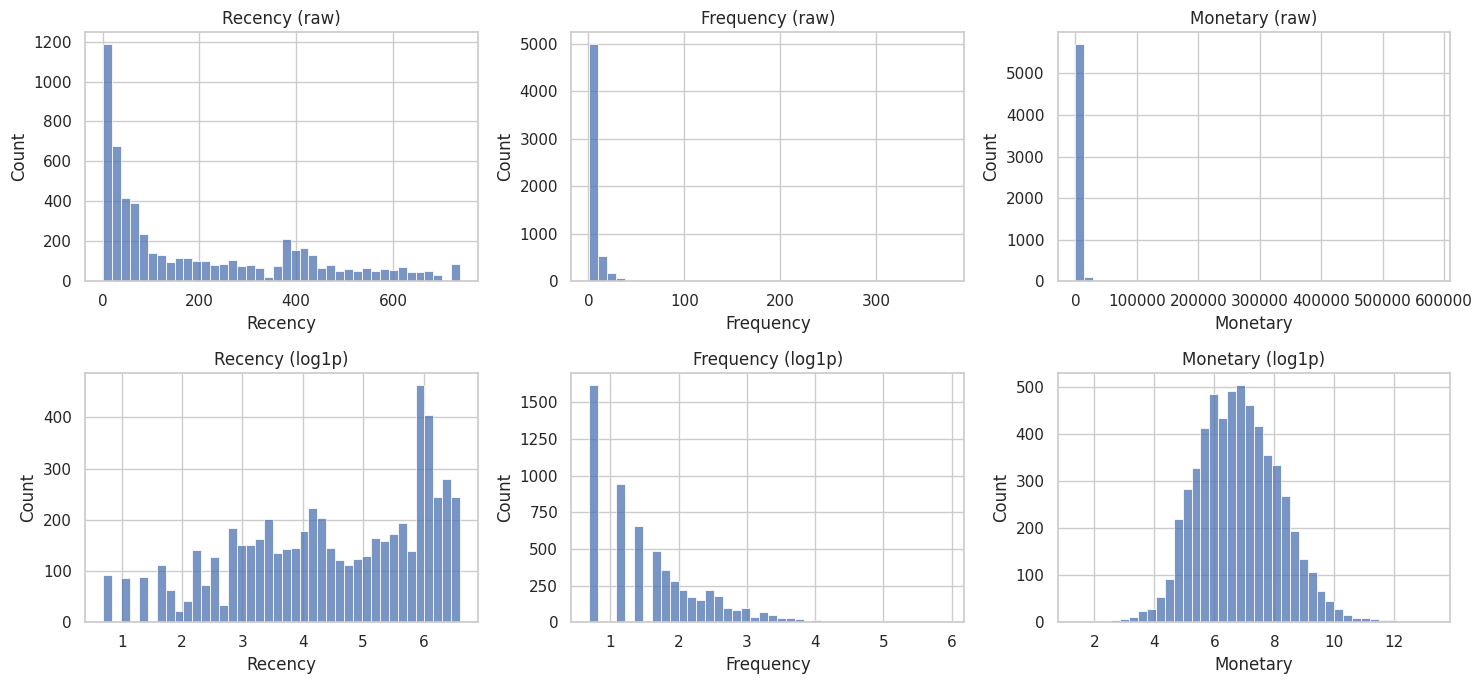

Scaled mean (should be ~0): [-0.  0. -0.]
Scaled std  (should be ~1): [1. 1. 1.]


In [6]:
rfm_log = np.log1p(rfm)                         # reduces right skew
scaler = StandardScaler()
X = scaler.fit_transform(rfm_log)               # zero mean, unit variance

fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for i, c in enumerate(["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm[c], bins=40, ax=ax[0, i]).set_title(f"{c} (raw)")
    sns.histplot(rfm_log[c], bins=40, ax=ax[1, i]).set_title(f"{c} (log1p)")
plt.tight_layout(); plt.show()

print("Scaled mean (should be ~0):", X.mean(axis=0).round(3))
print("Scaled std  (should be ~1):", X.std(axis=0).round(3))

### Observations: normalisation
- **Why:** K-Means uses Euclidean distance, so features on larger scales (Monetary in the thousands) would dominate Recency and Frequency. `StandardScaler` puts them on equal footing.
- **Key observation:** Recency: Raw data is right-skewed; log transformation makes the distribution more balanced.



  Frequency: Highly right-skewed in raw form, but log1p reduces the skewness.



  Monetary: Shows extreme right skew in raw data; after log1p, it becomes approximately bell-shaped.



  Key Insight: Log1p transformation reduces skewness and the impact of extreme values.



  Recommendation: Use log-transformed RFM values for further analysis and customer segmentation.
- **Why it matters:** without the log transform, clustering tends to give one huge cluster plus tiny outlier clusters.

## 5. K-Means: choosing K with the Elbow Method

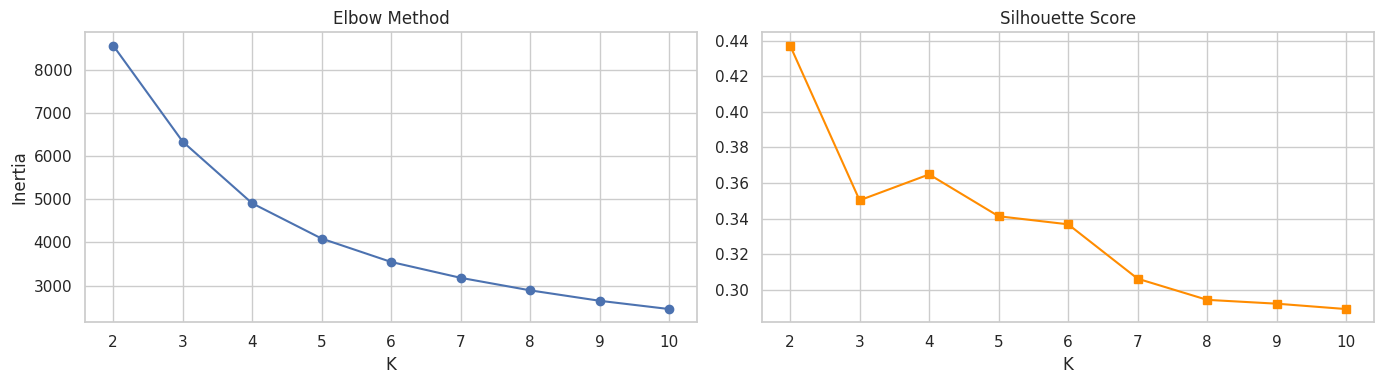

,inertia,silhouette
K,,
2,"8,558.69",0.44
3,"6,332.76",0.35
4,"4,904.52",0.36
5,"4,087.28",0.34
6,"3,546.07",0.34
7,"3,178.95",0.31
8,"2,888.91",0.29
9,"2,647.43",0.29
10,"2,455.91",0.29


In [7]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    m = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inertia.append(m.inertia_)
    sil.append(silhouette_score(X, m.labels_, sample_size=5000, random_state=RANDOM_STATE))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(list(ks), inertia, "o-"); ax[0].set(title="Elbow Method", xlabel="K", ylabel="Inertia")
ax[1].plot(list(ks), sil, "s-", color="darkorange"); ax[1].set(title="Silhouette Score", xlabel="K")
plt.tight_layout(); plt.show()

display(pd.DataFrame({"K": list(ks), "inertia": inertia, "silhouette": sil}).set_index("K"))

### Observations: choosing K
- **What it shows:** inertia (within-cluster variance) falls as K rises; the "elbow" is where extra clusters stop paying off. Silhouette measures cluster separation (higher is better).
- **Key observation:** Elbow Method: The elbow appears around K = 4–5, where the decrease in inertia starts slowing down.



  Silhouette Score: K = 2 has the highest score (~0.44), indicating better-separated clusters.



  Key Insight: K = 4 provides a reasonable balance between clustering quality and number of segments.




- **Decision:** Choose K = 4 to create four meaningful customer segments that are easier to understand and target with marketing strategies.

In [8]:
K = 4   # <- set this from the elbow/silhouette plots above
km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X)
rfm["Cluster"] = km.labels_
print("K =", K, "| Silhouette:", round(silhouette_score(X, km.labels_, sample_size=5000, random_state=RANDOM_STATE), 3))

K = 4 | Silhouette: 0.365


## 6. Visualise clusters (three feature combinations)

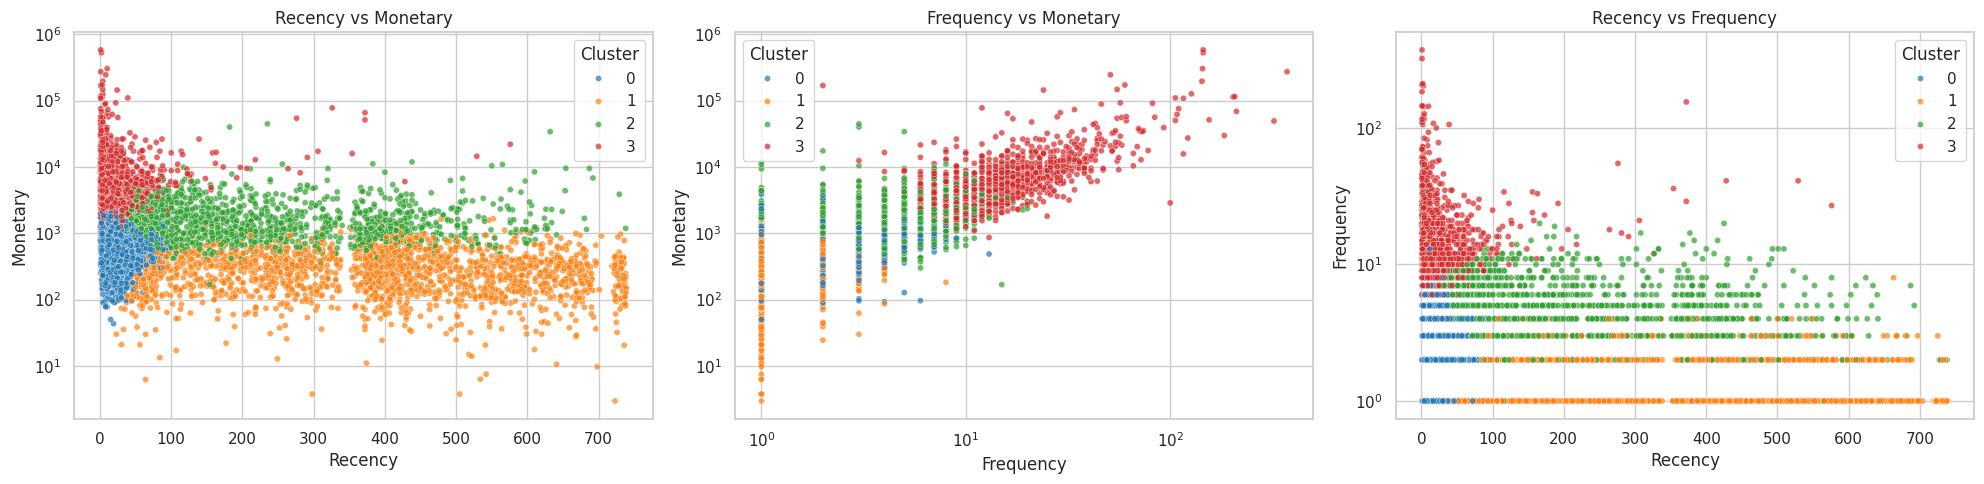

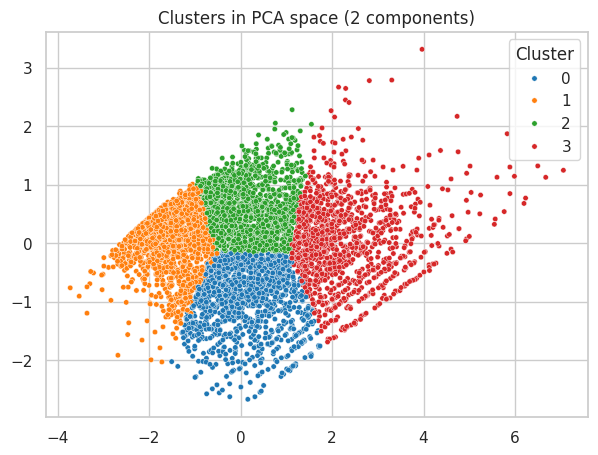

In [9]:
combos = [("Recency", "Monetary"), ("Frequency", "Monetary"), ("Recency", "Frequency")]
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
for a, (x, y) in zip(ax, combos):
    sns.scatterplot(data=rfm, x=x, y=y, hue="Cluster", palette="tab10", s=20, alpha=0.7, ax=a)
    a.set_title(f"{x} vs {y}")
    if y in ("Monetary", "Frequency"): a.set_yscale("log")
    if x == "Frequency": a.set_xscale("log")
plt.tight_layout(); plt.show()

p = PCA(2, random_state=RANDOM_STATE).fit_transform(X)
plt.figure(figsize=(7, 5))
sns.scatterplot(x=p[:, 0], y=p[:, 1], hue=rfm["Cluster"], palette="tab10", s=15)
plt.title("Clusters in PCA space (2 components)"); plt.show()

### Observations: cluster visualisation
- **What it shows:** each point is a customer, coloured by cluster, in three RFM views plus a PCA projection.
- **Key observation:** Recency vs Monetary: Shows good separation between low-, medium-, and high-value customer groups, though some overlap exists.



  Frequency vs Monetary: Shows a strong positive relationship, with high-frequency customers generally spending more.



  Recency vs Frequency: Clusters overlap considerably, indicating less distinct separation.



  PCA Visualization: The four clusters are reasonably well separated, with some boundary overlap.



  Key Insight: The clusters show distinct customer spending and purchasing patterns, although some overlap is expected in real-world RFM data.
- **Why it matters:** visible separation supports that the segments are distinct rather than arbitrary slices.

## 7. Cluster profiling

,Customers,Recency,Frequency,Monetary,% customers,% revenue
Cluster,,,,,,
0,1246,28.20,3.00,841.40,21.30,6.10
1,1968,392.50,1.40,317.00,33.60,3.70
2,1454,227.60,5.10,"1,923.40",24.80,16.40
3,1184,27.90,19.20,"10,642.20",20.20,73.80


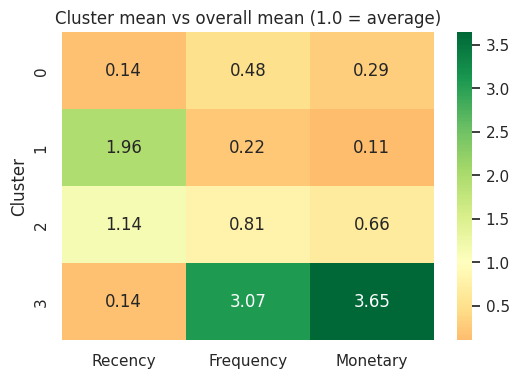

In [10]:
profile = rfm.groupby("Cluster").agg(
    Customers=("Recency", "size"),
    Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean"),
)
profile["% customers"] = profile["Customers"] / len(rfm) * 100
profile["% revenue"]   = rfm.groupby("Cluster")["Monetary"].sum() / rfm["Monetary"].sum() * 100
display(profile.round(1))

feat = ["Recency", "Frequency", "Monetary"]
rel = profile[feat] / rfm[feat].mean()        # relative to the overall customer average
plt.figure(figsize=(6, 4))
sns.heatmap(rel, annot=True, fmt=".2f", cmap="RdYlGn", center=1)
plt.title("Cluster mean vs overall mean (1.0 = average)"); plt.show()

### Observations: cluster profiles
- **What it shows:** mean Recency, Frequency and Monetary per cluster, with each cluster's share of customers and revenue.
- **Key observation:** - Cluster 0: Recent buyers (0.14 Recency) with low purchase frequency (0.48) and spending (0.29).
  - Cluster 1: Less recent buyers (1.96 Recency) with very low frequency (0.22) and monetary value (0.11).
  - Cluster 2: Moderately recent buyers (1.14 Recency) with moderate frequency (0.81) and spending (0.66).
  - Cluster 3: Recent buyers (0.14 Recency) with very high frequency (3.07) and spending (3.65).
  Key Insight: Cluster 3 represents the most valuable customers, while Cluster 1 represents the least engaged customers.


## 8. Number of customers per cluster

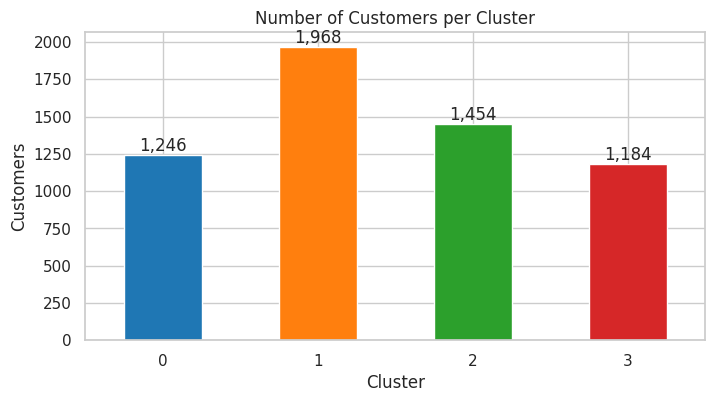

         % customers  % revenue
Cluster                        
0              21.30       6.10
1              33.60       3.70
2              24.80      16.40
3              20.20      73.80


In [11]:
ax = profile["Customers"].plot.bar(color=sns.color_palette("tab10", K), figsize=(8, 4))
for i, v in enumerate(profile["Customers"]):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.title("Number of Customers per Cluster"); plt.xlabel("Cluster"); plt.ylabel("Customers")
plt.xticks(rotation=0); plt.show()

print((profile[["% customers", "% revenue"]]).round(1))

### Observations: cluster sizes
- **What it shows:** how many customers fall in each cluster.
- **Key observation:** - Cluster 0: 21.3% of customers generate only 6.1% of revenue, indicating low-value customers.
  - Cluster 1: 33.6% of customers contribute 3.7% of revenue, representing the largest low-revenue segment.
  - Cluster 2: 24.8% of customers generate 16.4% of revenue, showing moderate customer value.
  - Cluster 3: Just 20.2% of customers generate 73.8% of total revenue, making them the most valuable segment.
  Key Insight: Cluster 3 contributes the majority of revenue despite having only 20.2% of customers.

  Recommendation: Prioritize retaining Cluster 3 customers through loyalty programs and personalized offers.
- **Why it matters:** it shows where marketing budget has the highest payoff and where it would be wasted.

## 9. Insights and recommended marketing actions

In [12]:
# Suggested labels from relative RFM position (rel: 1.0 = overall average). Always sanity-check against the table above.
def label(r):
    R, F, M = r["Recency"], r["Frequency"], r["Monetary"]
    if R < 1 and F > 1 and M > 1:   return "Champions"
    if R < 1:                       return "Recent / growing"
    if F > 1 or M > 1:              return "At risk (high value, lapsing)"
    return "Lost / low value"

actions = {
    "Champions": "VIP tier, early access to new products, referral rewards; avoid discounting, they already buy.",
    "Recent / growing": "Cross-sell and bundles, free-shipping threshold, nudge toward the next order.",
    "At risk (high value, lapsing)": "Time-limited personalised win-back offer; reach out before they are lost.",
    "Lost / low value": "Low-cost automated reactivation only, then stop spending on them.",
}
summary = profile[["Customers", "% customers", "% revenue"]].copy()
summary["Suggested segment"] = rel.apply(label, axis=1)
summary["Recommended action"] = summary["Suggested segment"].map(actions)
pd.set_option("display.max_colwidth", 200)
display(summary.round(1))

,Customers,% customers,% revenue,Suggested segment,Recommended action
Cluster,,,,,
0,1246,21.30,6.10,Recent / growing,"Cross-sell and bundles, free-shipping threshold, nudge toward the next order."
1,1968,33.60,3.70,Lost / low value,"Low-cost automated reactivation only, then stop spending on them."
2,1454,24.80,16.40,Lost / low value,"Low-cost automated reactivation only, then stop spending on them."
3,1184,20.20,73.80,Champions,"VIP tier, early access to new products, referral rewards; avoid discounting, they already buy."


### Marketing recommendations by segment
Match each cluster to the suggested label above (adjust names if your numbers say otherwise).

| Segment | Typical profile | Recommended action |
|---|---|---|
| **Champions** | Low recency, high frequency, highest spend | VIP/loyalty tier, early access, referral rewards. Do not discount. |
| **Recent / growing** | Recent buyers, medium frequency and spend | Cross-sell, bundles, free-shipping threshold to raise basket size. |
| **At risk** | Previously valuable, recency now high | Time-limited personalised win-back campaign. |
| **Lost / low value** | High recency, low frequency and spend | Cheap automated reactivation; stop spending if no response. |

### Limitations
- Data is from 2009-2011 from a single gift-ware retailer, so findings are illustrative, not current market insight.
- Wholesale customers skew Monetary; the log transform reduces but does not remove this.
- K is a judgment call; the elbow was *(clear / soft)* and silhouette values are modest because RFM data is continuous.
- CLV is historical spend, not predicted future value.